In [4]:
%pip install matplotlib seaborn


  Using cached matplotlib-3.11.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.9 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 2

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Load cleaned dataset
df = pd.read_csv("../data/processed/sales_cleaned.csv")

# to_datetime is use so that we can extract year , month , days
df["date"] = pd.to_datetime(df["date"])

print("Dataset loaded successfully")
print(df.shape)

Dataset loaded successfully
(913000, 4)


In [ ]:
# Overall sales analysis
print("Total units sold:", df["sales"].sum())

print("Average daily product sales:", df["sales"].mean())

print("Median sales:", df["sales"].median())

print("Maximum daily product sales:", df["sales"].max())

print("Minimum daily product sales:", df["sales"].min())

Total units sold: 47704512
Average daily product sales: 52.250286966046005
Median sales: 47.0
Maximum daily product sales: 231
Minimum daily product sales: 0


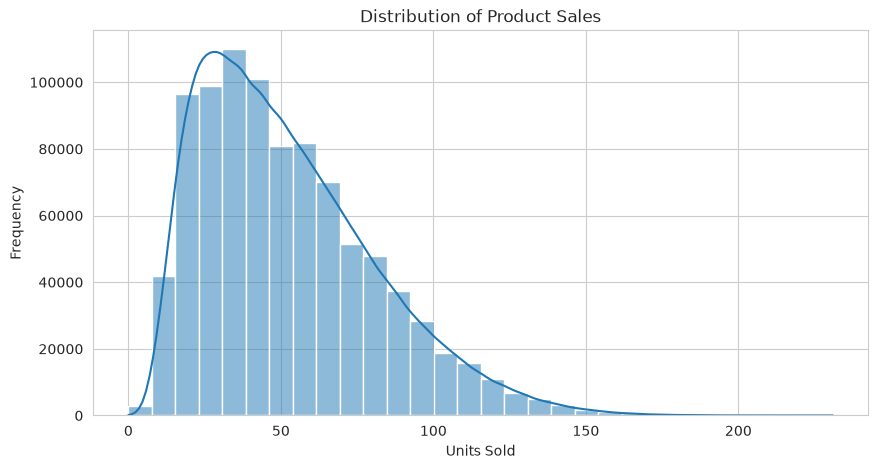

In [ ]:
# Sales distribution
plt.figure(figsize=(10, 5))

sns.histplot(df["sales"], bins=30, kde=True)

plt.title("Distribution of Product Sales")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")

plt.show()

In [ ]:
# Daily aggregation
daily_sales = df.groupby("date")["sales"].sum().reset_index()

daily_sales.head()

,date,sales
0,2013-01-01,13696
1,2013-01-02,13678
2,2013-01-03,14488
3,2013-01-04,15677
4,2013-01-05,16237


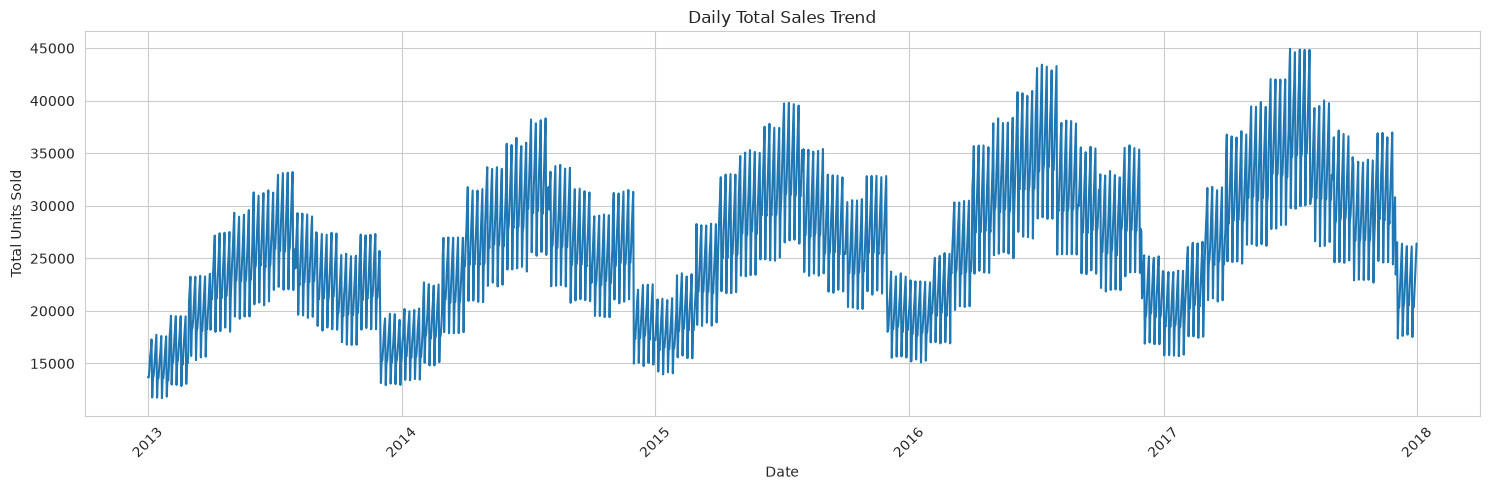

In [ ]:
# Plot daily sales
plt.figure(figsize=(15, 5))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"]
)

plt.title("Daily Total Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Monthly sales analysis
monthly_sales = df.copy()

monthly_sales["year_month"] = (
    monthly_sales["date"].dt.to_period("M")
)

monthly_sales = (
    monthly_sales.groupby("year_month")["sales"]
    .sum()
    .reset_index()
)

monthly_sales["year_month"] = (
    monthly_sales["year_month"].astype(str)
)

monthly_sales.head()

,year_month,sales
0,2013-01,454904
1,2013-02,459417
2,2013-03,617382
3,2013-04,682274
4,2013-05,763242


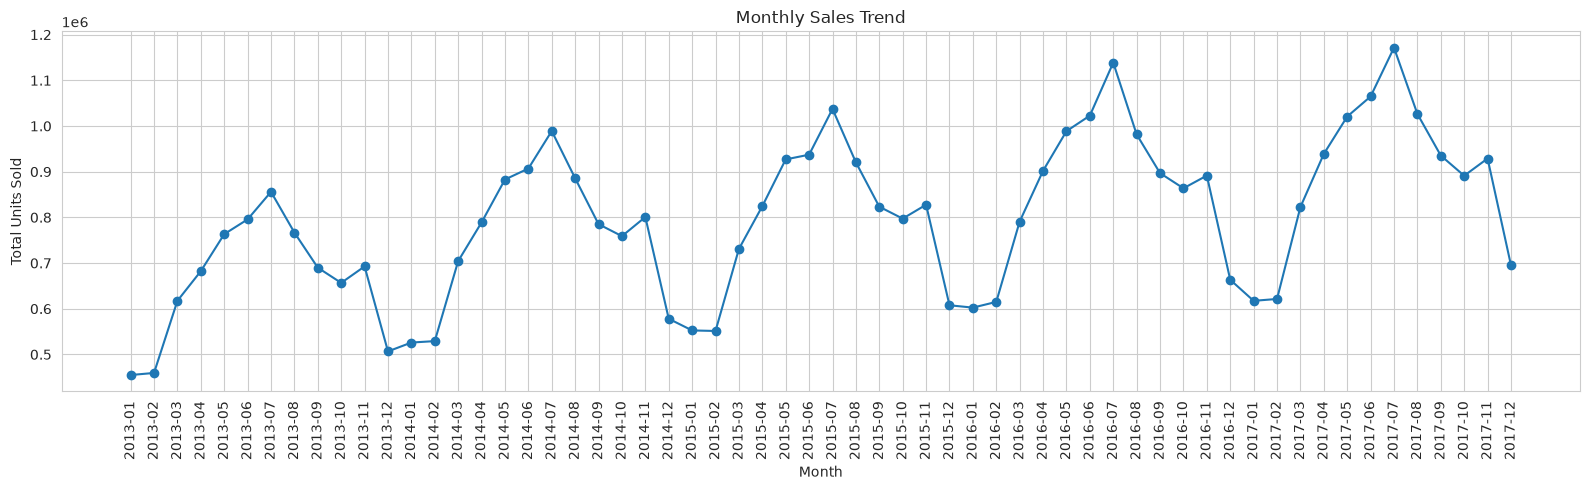

In [ ]:
# Monthly sales visualization
plt.figure(figsize=(16, 5))

plt.plot(
    monthly_sales["year_month"],
    monthly_sales["sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
# Store-wise sales analysis
store_sales = (
    df.groupby("store")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(store_sales)

store
2     6120128
8     5856169
3     5435144
10    5360158
9     5025976
4     5012639
1     4315603
5     3631016
6     3627670
7     3320009
Name: sales, dtype: int64


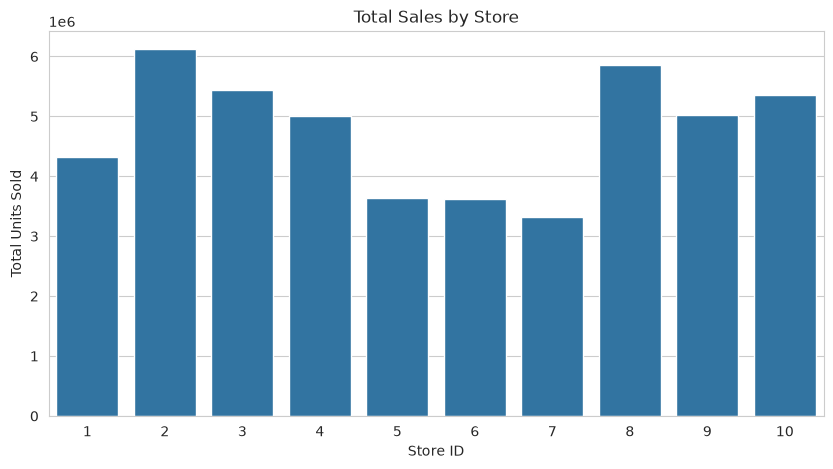

In [ ]:
# Visualize store performance
plt.figure(figsize=(10, 5))

sns.barplot(
    x=store_sales.index,
    y=store_sales.values
)

plt.title("Total Sales by Store")
plt.xlabel("Store ID")
plt.ylabel("Total Units Sold")

plt.show()

In [ ]:
# Product-wise sales analysis
product_sales = (
    df.groupby("item")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Products:")
print(product_sales.head(10))

print("\nBottom 10 Products:")
print(product_sales.tail(10))

Top 10 Products:
item
15    1607442
28    1604713
13    1539621
18    1538876
25    1473334
45    1471467
38    1470330
22    1469971
36    1406548
8     1405108
Name: sales, dtype: int64

Bottom 10 Products:
item
37    534258
40    534094
34    469935
16    468480
27    402628
4     401907
47    401781
41    401759
1     401384
5     335230
Name: sales, dtype: int64


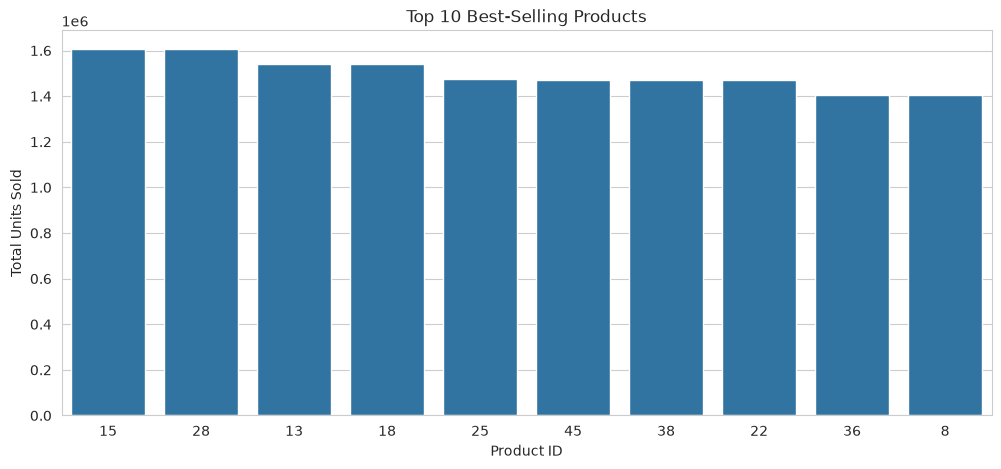

In [ ]:
# Visualize top 10 products
top_products = product_sales.head(10)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=top_products.index.astype(str),
    y=top_products.values
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")

plt.show()

In [ ]:
# Weekly sales pattern
df["day_name"] = df["date"].dt.day_name()

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_sales = (
    df.groupby("day_name")["sales"]
    .mean()
    .reindex(weekday_order)
)

print(weekday_sales)

day_name
Monday       41.429638
Tuesday      48.225908
Wednesday    48.368506
Thursday     51.723218
Friday       55.157249
Saturday     58.662697
Sunday       62.143333
Name: sales, dtype: float64


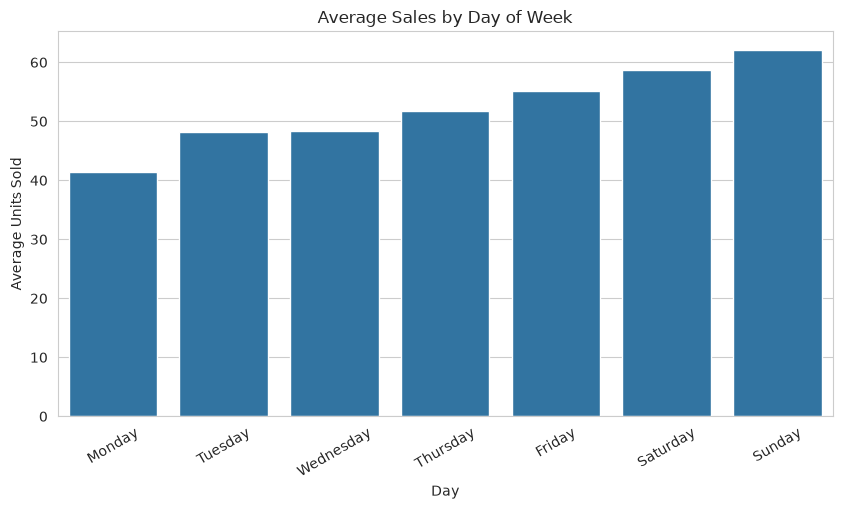

In [ ]:
# Visualize weekday sales
plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Units Sold")

plt.xticks(rotation=30)
plt.show()

In [ ]:
# Monthly seasonality analysis
df["month"] = df["date"].dt.month

month_sales = (
    df.groupby("month")["sales"]
    .mean()
)

print(month_sales)

month
1     35.524503
2     39.378397
3     47.305574
4     55.152893
5     59.128219
6     63.025480
7     66.998619
8     59.105226
9     55.072760
10    51.193806
11    55.218080
12    39.365265
Name: sales, dtype: float64


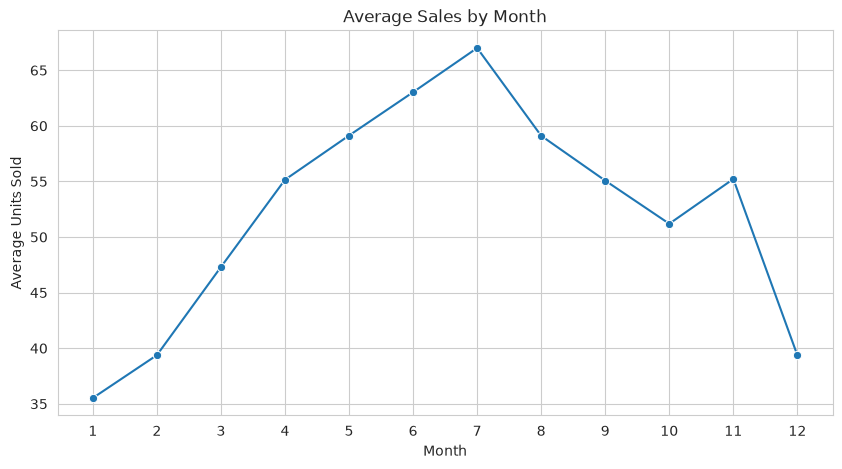

In [ ]:
# Visualization
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=month_sales.index,
    y=month_sales.values,
    marker="o"
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")

plt.xticks(range(1, 13))
plt.show()

In [ ]:
# Create a pivot table Store-product demand variation
store_item_sales = df.pivot_table(
    index="store",
    columns="item",
    values="sales",
    aggfunc="mean"
)

store_item_sales.head()


item,1,2,3,4,5,6,7,8,9,10,...,41,42,43,44,45,46,47,48,49,50
store,,,,,,,,,,,,,,,,,,,,,
1,19.971522,53.148959,33.208105,19.956188,16.612815,53.060789,52.783680,69.472070,46.504929,66.354326,...,20.002738,33.105696,46.242607,26.594195,72.720701,52.845016,19.814348,46.546002,26.461665,59.342826
2,28.173604,75.316539,46.992333,28.234940,23.540526,74.945235,75.058598,99.090361,65.478094,94.097481,...,28.069551,47.368018,65.785323,37.785871,103.381161,75.219606,28.187842,66.028478,37.711939,84.622125
3,25.070099,66.804491,41.771084,25.116101,20.857612,67.007119,66.647864,87.517525,58.486857,83.387733,...,24.989047,41.797371,58.197700,33.386090,91.851041,66.748083,25.120482,58.700986,33.259584,74.958379
4,22.938664,61.715225,38.548193,23.086528,19.525192,61.270537,61.625411,80.819825,54.043812,77.047645,...,23.168127,38.539978,54.018620,30.952355,84.687295,61.420044,23.114458,53.765608,30.840635,68.921687
5,16.739321,44.488499,27.835706,16.776561,14.086528,44.564622,44.535597,58.565717,38.837349,55.509858,...,16.830778,27.730559,39.163198,22.415115,61.427163,44.734940,16.699343,39.281490,22.371851,50.319277


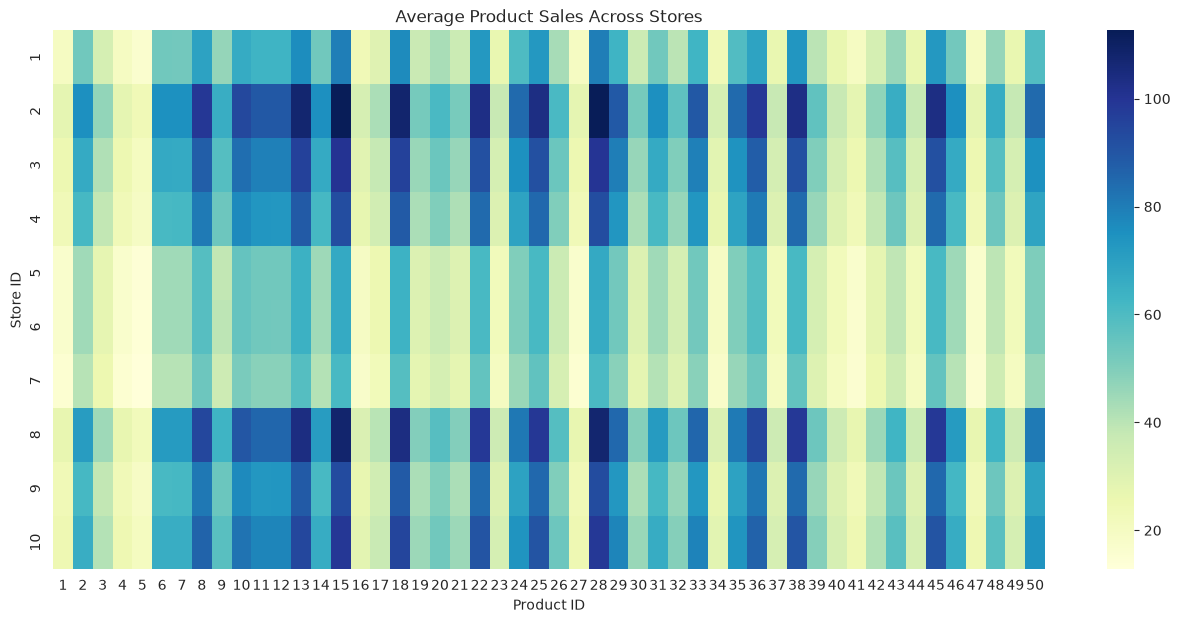

In [ ]:
# heatmap
plt.figure(figsize=(16, 7))

sns.heatmap(
    store_item_sales,
    cmap="YlGnBu"
)

plt.title("Average Product Sales Across Stores")
plt.xlabel("Product ID")
plt.ylabel("Store ID")

plt.show()

In [23]:
# Save aggregated datasets for future use

daily_sales.to_csv(
    "../data/processed/daily_sales.csv",
    index=False
)

store_sales.to_csv(
    "../data/processed/store_sales.csv"
)

product_sales.to_csv(
    "../data/processed/product_sales.csv"
)

print("EDA aggregation files saved successfully")

EDA aggregation files saved successfully
